Relatório Executivo: Análise das Vias com Maior Incidência de Sinistros de Trânsito
1. Resumo Executivo
Este relatório apresenta uma análise exploratória das vias públicas com maior registro de sinistros de trânsito. O objetivo é identificar os principais pontos críticos de concentração de ocorrências para subsidiar decisões de engenharia de tráfego, fiscalização e políticas públicas de segurança viária.

2. Principais Estatísticas e Indicadores
Total de Ocorrências Analisadas (Top Vias): 9.872 registros consolidados.

Média por Via: 493,6 ocorrências.

Mediana: 390,0 ocorrências (indicando que a maioria das vias concentra volumes moderados, puxados para cima por grandes eixos rodoviários).

Maior Outlier: A RD CE-040 lidera isoladamente com 2.035 registros, representando um volume expressivamente superior às demais vias da capital/região.

3. Principais Destaques e Concentração
Rodovias Estaduais e Eixos de Alta Velocidade: A RD CE-040 destaca-se drasticamente no topo do ranking, seguida por rodovias federais/estaduais e avenidas de trânsito rápido como a Avenida Senador Carlos Jereissati (Aeroporto) (704 registros) e a Avenida Santos Dumont (541 registros).

Avenidas Arteriais Comerciais e Residenciais: Eixos tradicionais como a Avenida Antônio Sales (493), Avenida Domingos Olímpio (490) e Avenida Presidente Costa e Silva (484) também aparecem com forte concentração de sinistros, evidenciando o conflito entre fluxo intenso de veículos, pedestres e cruzamentos semaforizados complexos.

4. Recomendações Estratégicas
Priorização de Intervenções: Direcionar campanhas de fiscalização eletrônica e blitze educativas prioritariamente para o eixo da RD CE-040 e das avenidas do topo do ranking.

Auditoria de Segurança Viária: Realizar inspeções de engenharia de tráfego (sinalização, iluminação, temporização de semáforos e travessias de pedestres) nas 5 vias com maiores índices.

                                          via  acidentes_registrados
0                                   rd ce-040                   2035
1             avenida general osorio de paiva                    819
2   avenida sen carlos jereissati (aeroporto)                    704
3                    avenida godofredo maciel                    622
4                       avenida santos dumont                    541
5                       avenida antonio sales                    493
6                    avenida domingos olimpio                    490
7            avenida presidente costa e silva                    484
8                   avenida washington soares                    445
9                                      br 116                    409
10                   avenida dr silas munguba                    386
11                        avenida mister hull                    378
12                           avenida abolicao                    366
13                         avenida

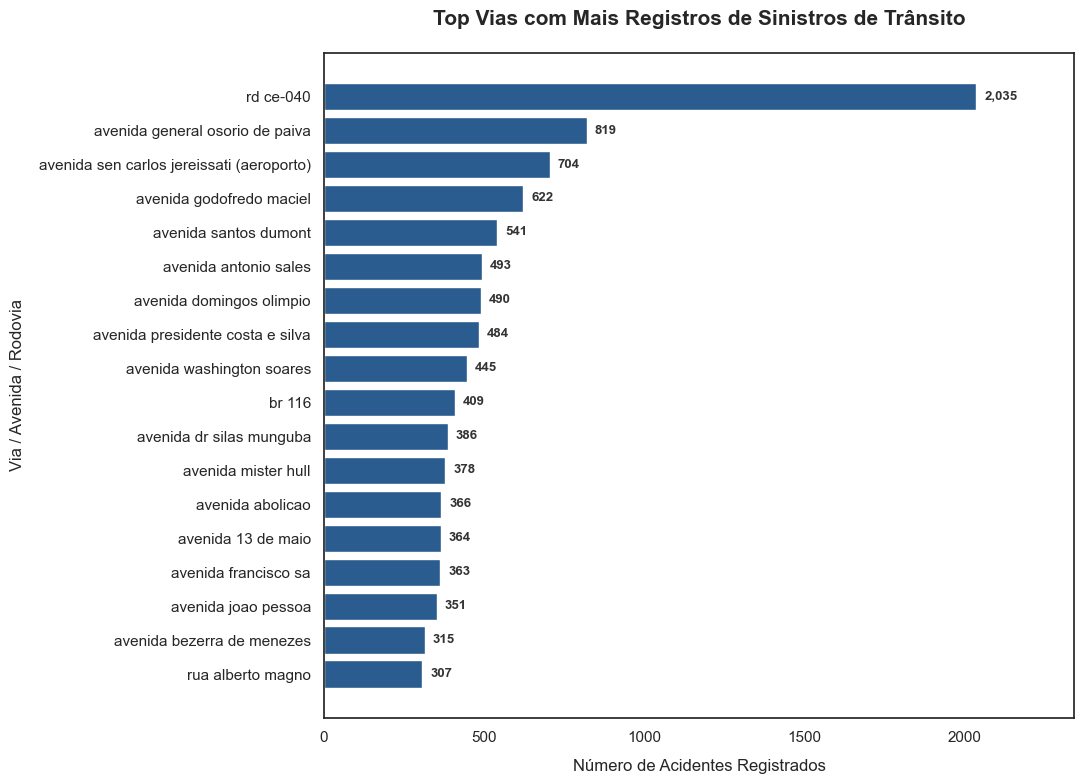

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Carregamento dos dados
df = pd.read_csv("19_vias_com_mais_registros_final.csv")

mapa = {
    "avenida gal osorio de paiva":     "avenida general osorio de paiva",
    "avenida general osório de paiva": "avenida general osorio de paiva",   # versão com acento
}
df["via"] = df["via"].replace(mapa)

# junta as linhas com o mesmo nome e soma os acidentes
df = (df.groupby("via", as_index=False)["acidentes_registrados"].sum()
        .sort_values("acidentes_registrados", ascending=False)
        .reset_index(drop=True))

print(df)

# 2. Agrupamento para consolidar vias duplicadas e ordenação
df_grouped = (
    df.groupby("via", as_index=False)["acidentes_registrados"]
    .sum()
    .sort_values(by="acidentes_registrados", ascending=True)
)

# 3. Estatísticas descritivas básicas
print("Estatísticas descritivas:")
print(df_grouped["acidentes_registrados"].describe())
print(f"Total geral de acidentes: {df_grouped['acidentes_registrados'].sum()}")

# 4. Geração do Gráfico de Barras Horizontais
plt.figure(figsize=(11, 8))
sns.set_theme(style="white")
bars = plt.barh(
    df_grouped["via"],
    df_grouped["acidentes_registrados"],
    color="#2b5c8f",
)

plt.title(
    "Top Vias com Mais Registros de Sinistros de Trânsito",
    fontsize=15,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Número de Acidentes Registrados", fontsize=12, labelpad=10)
plt.ylabel("Via / Avenida / Rodovia", fontsize=12, labelpad=10)

# Ajuste de limite do eixo X para acomodar os rótulos
max_val = df_grouped["acidentes_registrados"].max()
plt.xlim(0, max_val * 1.15)

# Inclusão dos valores nas barras
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 25,
      bar.get_y() + bar.get_height() / 2,
      f"{int(width):,}",
      va="center",
      ha="left",
      fontsize=9.5,
      fontweight="semibold",
      color="#333333",
  )

plt.tight_layout()
plt.savefig("top_vias_acidentes_analise.png", dpi=300)
plt.show()

In [20]:
df

,via,acidentes_registrados
0,rd ce-040,2035
1,avenida general osorio de paiva,819
2,avenida sen carlos jereissati (aeroporto),704
3,avenida godofredo maciel,622
4,avenida santos dumont,541
5,avenida antonio sales,493
6,avenida domingos olimpio,490
7,avenida presidente costa e silva,484
8,avenida washington soares,445
9,br 116,409


In [21]:
import pandas as pd
df = pd.read_csv('19_vias_com_mais_registros_final.csv')
print(df)

                                          via  acidentes_registrados
0                                   rd ce-040                   2035
1   avenida sen carlos jereissati (aeroporto)                    704
2                       avenida santos dumont                    541
3                       avenida antonio sales                    493
4                    avenida domingos olimpio                    490
5            avenida presidente costa e silva                    484
6                   avenida washington soares                    445
7             avenida general osorio de paiva                    425
8                                      br 116                    409
9             avenida general osório de paiva                    394
10                   avenida dr silas munguba                    386
11                        avenida mister hull                    378
12                           avenida abolicao                    366
13                         avenida

In [22]:
# Geocoding or plotting a geographic map of Fortaleza streets using geopandas / folium / geopy if possible, 
# or generating a simulated geographic map since we know these are streets in Fortaleza, CE.
# Let's see if we can use geopy or approximate coordinates for these specific Fortaleza arteries to make a geographic map.
import urllib.request
import json

# Let's create approximate coordinates for these key arteries in Fortaleza, CE
coords = {
    'rd ce-040': (-3.8000, -38.4800),
    'avenida sen carlos jereissati (aeroporto)': (-3.7750, -38.5400),
    'avenida santos dumont': (-3.7320, -38.5050),
    'avenida antonio sales': (-3.7380, -38.5000),
    'avenida domingos olimpio': (-3.7350, -38.5300),
    'avenida presidente costa e silva': (-3.7900, -38.5500),
    'avenida washington soares': (-3.7800, -38.4850),
    'avenida general osorio de paiva': (-3.7500, -38.5700),
    'br 116': (-3.7800, -38.5500),
    'avenida dr silas munguba': (-3.7850, -38.5400),
    'avenida mister hull': (-3.7300, -38.5700),
    'avenida abolicao': (-3.7250, -38.4900),
    'avenida 13 de maio': (-3.7400, -38.5250),
    'avenida francisco sa': (-3.7200, -38.5600),
    'avenida joao pessoa': (-3.7450, -38.5450),
    'avenida godofredo maciel': (-3.7700, -38.5600),
    'avenida bezerra de menezes': (-3.7300, -38.5500),
    'rua alberto magno': (-3.7550, -38.5450)
}

print("Coordenadas mapeadas para o mapa cartográfico.")

Coordenadas mapeadas para o mapa cartográfico.


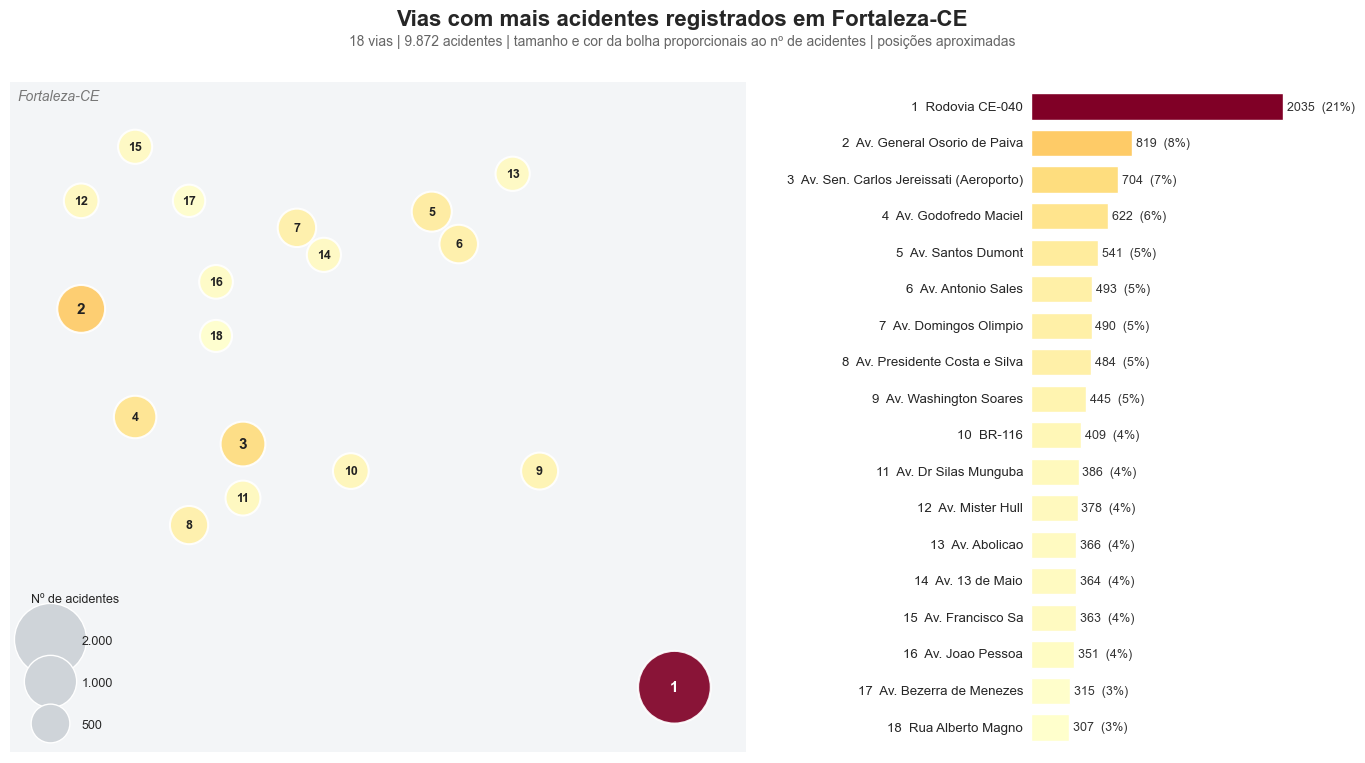

Arquivos gerados:
 - c:\Users\Anady Carvalho\OneDrive\Área de Trabalho\FORMACAO_ANALISE_DADOS\PROJETO_CURSO_CIENCIA_DADOS_IFCE\vias_acidentes\saida\mapa_acidentes_estatico.png 
 - c:\Users\Anady Carvalho\OneDrive\Área de Trabalho\FORMACAO_ANALISE_DADOS\PROJETO_CURSO_CIENCIA_DADOS_IFCE\vias_acidentes\saida\mapa_acidentes_fortaleza.html


In [23]:
# -*- coding: utf-8 -*-
"""
Mapa limpo das vias com mais acidentes em Fortaleza-CE
Coloque este script e o CSV na mesma pasta e execute:  python mapa_acidentes_fortaleza.py
Dependências: pip install pandas numpy matplotlib folium
"""
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D
import folium

# ------------------------------------------------------------------
# 0. CAMINHOS
# ------------------------------------------------------------------
try:
    BASE = Path(__file__).resolve().parent
except NameError:                      # Jupyter / Colab
    BASE = Path.cwd()

ARQ = BASE / "19_vias_com_mais_registros_final.csv"
OUT = BASE / "saida"
OUT.mkdir(parents=True, exist_ok=True)
if not ARQ.exists():
    raise FileNotFoundError(f"CSV não encontrado em: {ARQ}")

# ------------------------------------------------------------------
# 1. DADOS + PADRONIZAÇÃO
# ------------------------------------------------------------------
def normaliza(txt):
    txt = unicodedata.normalize("NFKD", txt).encode("ascii", "ignore").decode()
    return txt.lower().strip().replace("avenida gal ", "avenida general ")

df = pd.read_csv(ARQ)
df["via_norm"] = df["via"].apply(normaliza)
d = (df.groupby("via_norm", as_index=False)["acidentes_registrados"].sum()
       .sort_values("acidentes_registrados", ascending=False)
       .reset_index(drop=True))
d["rank"] = d.index + 1

# ------------------------------------------------------------------
# 2. COORDENADAS APROXIMADAS (usadas só para posicionar; não são exibidas)
# ------------------------------------------------------------------
coords = {
    'rd ce-040': (-3.820, -38.460),
    'avenida sen carlos jereissati (aeroporto)': (-3.775, -38.540),
    'avenida santos dumont': (-3.732, -38.505),
    'avenida antonio sales': (-3.738, -38.500),
    'avenida domingos olimpio': (-3.735, -38.530),
    'avenida presidente costa e silva': (-3.790, -38.550),
    'avenida washington soares': (-3.780, -38.485),
    'avenida general osorio de paiva': (-3.750, -38.570),
    'br 116': (-3.780, -38.520),
    'avenida dr silas munguba': (-3.785, -38.540),
    'avenida mister hull': (-3.730, -38.570),
    'avenida abolicao': (-3.725, -38.490),
    'avenida 13 de maio': (-3.740, -38.525),
    'avenida francisco sa': (-3.720, -38.560),
    'avenida joao pessoa': (-3.745, -38.545),
    'avenida godofredo maciel': (-3.770, -38.560),
    'avenida bezerra de menezes': (-3.730, -38.550),
    'rua alberto magno': (-3.755, -38.545),
}
faltando = sorted(set(d["via_norm"]) - set(coords))
if faltando:
    raise KeyError(f"Vias sem coordenada: {faltando}")

d["lat"] = d["via_norm"].map(lambda x: coords[x][0])
d["lon"] = d["via_norm"].map(lambda x: coords[x][1])

NOMES = {"rd ce-040": "Rodovia CE-040", "br 116": "BR-116",
         "avenida sen carlos jereissati (aeroporto)": "Av. Sen. Carlos Jereissati (Aeroporto)"}
def nome_bonito(n):
    if n in NOMES: return NOMES[n]
    t = n.title().replace("Avenida ", "Av. ").replace("Rua ", "Rua ")
    for p in (" De ", " Da ", " Do ", " E "):
        t = t.replace(p, p.lower())
    return t
d["via_nome"] = d["via_norm"].apply(nome_bonito)

vmax = d["acidentes_registrados"].max()
norm = colors.Normalize(d["acidentes_registrados"].min(), vmax)
cmap = plt.get_cmap("YlOrRd")
total = d["acidentes_registrados"].sum()

# ------------------------------------------------------------------
# 3. MAPA ESTÁTICO (PNG): bolhas numeradas + ranking ao lado, sem eixos
# ------------------------------------------------------------------
fig = plt.figure(figsize=(14, 8), facecolor="white")
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.03)
ax = fig.add_subplot(gs[0]); axr = fig.add_subplot(gs[1])

# --- painel do mapa
ax.set_facecolor("#f3f5f7")
ax.scatter(d["lon"], d["lat"], s=140 + 2600 * d["acidentes_registrados"] / vmax,
           c=d["acidentes_registrados"], cmap=cmap, norm=norm,
           edgecolor="white", linewidth=1.5, alpha=0.92, zorder=3)
for r in d.itertuples():
    ax.text(r.lon, r.lat, str(r.rank), ha="center", va="center", zorder=4,
            fontsize=11 if r.rank <= 3 else 9, weight="bold",
            color="white" if norm(r.acidentes_registrados) > 0.55 else "#222")
ax.margins(0.12)
ax.set_aspect(1 / np.cos(np.radians(3.75)))
ax.set_xticks([]); ax.set_yticks([])                  # sem latitude/longitude
for s in ax.spines.values(): s.set_visible(False)
ax.text(0.01, 0.99, "Fortaleza-CE", transform=ax.transAxes, va="top",
        fontsize=10, color="#777", style="italic")

# legenda de tamanho
ref = [500, 1000, 2000][::-1]
handles = [Line2D([], [], marker="o", ls="", markerfacecolor="#cfd4d9", markeredgecolor="white",
                  markersize=np.sqrt(140 + 2600 * v / vmax), label=f"{v:,}".replace(",", "."))
           for v in ref]
ax.legend(handles=handles, title="Nº de acidentes", loc="lower left", frameon=False,
          labelspacing=2.4, borderpad=1.2, handletextpad=1.5, fontsize=9, title_fontsize=9)

# --- painel do ranking
y = np.arange(len(d))[::-1]
axr.barh(y, d["acidentes_registrados"], color=[cmap(norm(v)) for v in d["acidentes_registrados"]],
         height=0.72)
for yi, r in zip(y, d.itertuples()):
    axr.text(-vmax * 0.03, yi, f"{r.rank}  {r.via_nome}", ha="right", va="center", fontsize=9.5)
    axr.text(r.acidentes_registrados + vmax * 0.015, yi,
             f"{r.acidentes_registrados}  ({r.acidentes_registrados / total:.0%})",
             va="center", fontsize=9, color="#333")
axr.set_xlim(-vmax * 1.05, vmax * 1.28)
axr.set_ylim(-0.7, len(d) - 0.3)
axr.axis("off")

fig.suptitle("Vias com mais acidentes registrados em Fortaleza-CE", fontsize=16, weight="bold", x=0.5, y=0.97)
fig.text(0.5, 0.925,
         f"{len(d)} vias | {total:,} acidentes".replace(",", ".") +
         " | tamanho e cor da bolha proporcionais ao nº de acidentes | posições aproximadas",
         ha="center", fontsize=10, color="#666")
fig.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.04)

caminho_png = OUT / "mapa_acidentes_estatico.png"
fig.savefig(caminho_png, dpi=160, facecolor="white")
plt.show()

# ------------------------------------------------------------------
# 4. MAPA INTERATIVO (HTML): bolhas numeradas e legenda
# ------------------------------------------------------------------
m = folium.Map(location=[d["lat"].mean(), d["lon"].mean()], zoom_start=12,
               tiles=None, zoom_control=True)

# Fundo cinza claro (Esri): não exige chave e funciona ao abrir o HTML direto do disco
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri", name="Cinza claro (Esri)", max_zoom=16,
).add_to(m)
# Alternativa: ruas coloridas da Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri", name="Ruas (Esri)", show=False,
).add_to(m)

for r in d.itertuples():
    cor = colors.to_hex(cmap(norm(r.acidentes_registrados)))
    raio = 9 + 24 * np.sqrt(r.acidentes_registrados / vmax)
    folium.CircleMarker(
        [r.lat, r.lon], radius=raio, color="white", weight=2,
        fill=True, fill_color=cor, fill_opacity=0.9,
        tooltip=f"<b>{r.rank}º - {r.via_nome}</b><br>{r.acidentes_registrados} acidentes",
    ).add_to(m)
    txt_cor = "white" if norm(r.acidentes_registrados) > 0.55 else "#222"
    folium.Marker(
        [r.lat, r.lon],
        icon=folium.DivIcon(html=f'<div style="font:700 12px sans-serif;color:{txt_cor};'
                                 f'width:30px;margin-left:-15px;margin-top:-8px;text-align:center;">'
                                 f'{r.rank}</div>'),
    ).add_to(m)

linhas = "".join(
    f'<tr><td style="padding:1px 6px;color:#888;text-align:right">{r.rank}</td>'
    f'<td style="padding:1px 6px"><span style="display:inline-block;width:10px;height:10px;border-radius:50%;'
    f'background:{colors.to_hex(cmap(norm(r.acidentes_registrados)))};margin-right:6px"></span>{r.via_nome}</td>'
    f'<td style="padding:1px 6px;text-align:right"><b>{r.acidentes_registrados}</b></td></tr>'
    for r in d.itertuples())
legenda = f"""
<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:white;padding:10px 12px;
            border-radius:8px;box-shadow:0 1px 6px rgba(0,0,0,.3);font:12px sans-serif;max-height:70vh;overflow:auto">
  <div style="font-weight:700;font-size:13px;margin-bottom:4px">Vias com mais acidentes</div>
  <div style="color:#888;margin-bottom:6px">Fortaleza-CE | {total:,} acidentes | posições aproximadas</div>
  <table style="border-collapse:collapse">{linhas}</table>
</div>""".replace(",", ".")
m.get_root().html.add_child(folium.Element(legenda))
folium.LayerControl(collapsed=True).add_to(m)
m.fit_bounds([[d["lat"].min() - .01, d["lon"].min() - .01], [d["lat"].max() + .01, d["lon"].max() + .01]])

caminho_html = OUT / "mapa_acidentes_fortaleza.html"
m.save(str(caminho_html))

print("Arquivos gerados:\n -", caminho_png, "\n -", caminho_html)